# Neural Band: foundation models (zero-shot + fine-tuned)
**Owner: Srija** · AST, PANNs (CNN14) and CLAP on IRMAS

This notebook adds the foundation-model part of the project **without changing any existing file**. It writes three new files next to the TODO stubs:

| New file | What it does |
|---|---|
| `src/foundation/common.py` | Shared loading (same manifest, splits and `load_clip` cleaning as everyone else), the three model wrappers, cached embeddings |
| `src/foundation/zero_shot/run_zero_shot.py` | Zero-shot: AudioSet label mapping for AST / PANNs, text prompts for CLAP |
| `src/foundation/finetune/train_finetune.py` | Linear probe and fine-tuning on every 5–100% training subset |

**Before you start:** Runtime → Change runtime type → **T4 GPU** (or better).

Everything important (IRMAS zip, cached embeddings, results) is saved to Google Drive in `MyDrive/neural_band/`, so if Colab disconnects you just re-run the setup cells and carry on. Re-running a training cell replaces the matching rows in `results.csv` rather than duplicating them.

Rough times on a T4: setup + data 10–15 min the first time · zero-shot ~10 min · linear probe ~5 min · fine-tuning AST/CLAP ~20–40 min per subset at 100% (much less on the small subsets).

## 1. Setup

In [1]:
!nvidia-smi -L || echo "No GPU: Runtime > Change runtime type > T4 GPU"

from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE = '/content/drive/MyDrive/neural_band'      # change if you want another folder
REPO  = '/content/repo'
os.makedirs(DRIVE, exist_ok=True)

GPU 0: Tesla T4 (UUID: GPU-94440305-7134-aaa5-7ed9-5cfe6d2e0054)
Mounted at /content/drive


In [2]:
# Clone (or update) the team repo and install requirements
if not os.path.exists(REPO):
    !git clone https://github.com/Srija-d/Neural-Band-instrument-recognition-.git {REPO}
else:
    !git -C {REPO} pull
%cd {REPO}
!pip install -q -r requirements.txt

Cloning into '/content/repo'...
remote: Enumerating objects: 131, done.
remote: Counting objects: 100% (131/131), done.
remote: Compressing objects: 100% (89/89), done.
remote: Total 131 (delta 49), reused 85 (delta 38), pack-reused 0 (from 0)
Receiving objects: 100% (131/131), 3.43 MiB | 9.86 MiB/s, done.
Resolving deltas: 100% (49/49), done.
/content/repo


In [ ]:
# IRMAS training data (~3 GB). The zip is kept on Drive so it is only downloaded once.
ZIP_DRIVE = f'{DRIVE}/IRMAS-TrainingData.zip'
os.makedirs('data', exist_ok=True)
if os.path.exists(ZIP_DRIVE) and not os.path.exists('data/IRMAS-TrainingData.zip'):
    !cp "{ZIP_DRIVE}" data/
!python scripts/download_irmas.py
if not os.path.exists(ZIP_DRIVE) and os.path.exists('data/IRMAS-TrainingData.zip'):
    !cp data/IRMAS-TrainingData.zip "{DRIVE}/"
!find data/IRMAS-TrainingData -name "*.wav" | wc -l   # should be 6705

Extracting...
Done: 6705 wav files in /content/repo/data/IRMAS-TrainingData
6705


In [3]:
import os
REPO = '/content/repo'
if not os.path.exists(REPO):
    !git clone https://github.com/Srija-d/Neural-Band-instrument-recognition-.git {REPO}
%cd {REPO}
!pip install -q -r requirements.txt
!pwd

/content/repo
/content/repo


In [4]:
# Restore cached waveforms / embeddings and earlier results from Drive (no-op on the first run)
!mkdir -p cache/foundation results/foundation
!rsync -a "{DRIVE}/cache_foundation/" cache/foundation/ 2>/dev/null || true
!rsync -a "{DRIVE}/results_foundation/" results/foundation/ 2>/dev/null || true

def save_to_drive():
    """Copy results and caches to Drive. Called after every experiment cell."""
    os.system(f'rsync -a results/foundation/ "{DRIVE}/results_foundation/"')
    os.system(f'rsync -a cache/foundation/ "{DRIVE}/cache_foundation/"')
    print('saved to', DRIVE)

In [5]:
import os
print('DRIVE =', DRIVE)
print('Drive mounted:', os.path.exists('/content/drive/MyDrive'))
print('cache restored:', os.listdir('cache/foundation'))
print('results restored:', os.listdir('results/foundation'))

DRIVE = /content/drive/MyDrive/neural_band
Drive mounted: True
cache restored: ['wave_48000.npy', 'wave_16000.npy', 'wave_16000_paths.csv', 'wave_32000.npy', 'wave_32000_paths.csv', 'wave_48000_paths.csv', 'ast_feats.npz', 'panns_feats.npz', 'clap_feats.npz']
results restored: ['zero_shot', 'finetune']


## 2. Write the new code files
These are **new** files; the existing stubs (`run.py`, `train.py`) and everyone else's code are left untouched. They reuse `load_clip`, the split CSVs, `split_indices` from the CNN script and `evaluate` from `src/evaluation/metrics.py`, so all models are scored on exactly the same clips.

In [6]:
%%writefile src/foundation/common.py
"""Shared code for the foundation-model experiments (zero-shot, linear probe, fine-tuning). Owner: Srija.

Uses the same clips, splits and cleaning as the rest of the project:
  * clip list and train/val/test/subset membership come from irmas_prep/manifest.csv
    (written by preprocess_irmas.py); if it doesn't exist yet, the same manifest is
    rebuilt from results/splits/*.csv with preprocess_irmas.build_manifest.
  * every clip is cleaned with src.preprocessing.audio.load_clip (trim silence,
    peak-normalize, exactly 3 s), only resampled to each model's own rate
    (AST 16 kHz, PANNs 32 kHz, CLAP 48 kHz).

Expensive things are cached under cache/foundation/ (gitignored):
  * wave_<sr>.npy   cleaned waveforms, float16, one row per manifest row
  * <model>_feats.npz  frozen embeddings (+ AudioSet probabilities for AST / PANNs)
"""
from __future__ import annotations

import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from tqdm import tqdm

from src.config import CLASS_CODES, CLIP_SECONDS, IRMAS_TRAIN_DIR, SPLITS_DIR
from src.cnn.train_cnn import SUBSET_COLS, pick_device, set_seed, split_indices  # noqa: F401  (re-exported)
from src.preprocessing.audio import load_clip

MODELS = ["ast", "panns", "clap"]
MODEL_SR = {"ast": 16000, "panns": 32000, "clap": 48000}
CHECKPOINTS = {
    "ast": "MIT/ast-finetuned-audioset-10-10-0.4593",   # AST fine-tuned on AudioSet (527 labels)
    "panns": "Cnn14_mAP=0.431.pth",                      # PANNs CNN14, downloaded by panns_inference
    "clap": "laion/clap-htsat-unfused",                  # LAION CLAP, HTS-AT audio encoder
}
DEFAULT_CACHE = Path("cache/foundation")


# --------------------------------------------------------------------------- data

def load_manifest(prep_dir: Path = Path("irmas_prep"), data_dir: Path = IRMAS_TRAIN_DIR) -> pd.DataFrame:
    """The shared manifest: path, label, recording_id, split, pct_005 ... pct_100."""
    path = Path(prep_dir) / "manifest.csv"
    if path.exists():
        return pd.read_csv(path)
    print(f"{path} not found; rebuilding the same manifest from {SPLITS_DIR}")
    from preprocess_irmas import build_manifest  # repo-root script, same logic as preprocessing
    return build_manifest(Path(data_dir), SPLITS_DIR)


def labels_to_ids(manifest: pd.DataFrame) -> np.ndarray:
    return manifest["label"].astype(str).map({c: i for i, c in enumerate(CLASS_CODES)}).to_numpy()


def _load_one(args):
    path, sr = args
    return load_clip(path, sr=sr).astype(np.float16)


def load_waveforms(manifest: pd.DataFrame, sr: int, data_dir: Path = IRMAS_TRAIN_DIR,
                   cache_dir: Path = DEFAULT_CACHE, workers: int | None = None) -> np.ndarray:
    """Cleaned 3 s waveforms at `sr`, shape (N, sr * 3), float16, row-aligned with the manifest.

    Built once (a few minutes) and memory-mapped afterwards.
    """
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    out = cache_dir / f"wave_{sr}.npy"
    keys = cache_dir / f"wave_{sr}_paths.csv"
    if out.exists() and keys.exists() and pd.read_csv(keys)["path"].tolist() == manifest["path"].tolist():
        return np.load(out, mmap_mode="r")

    from concurrent.futures import ProcessPoolExecutor
    n, length = len(manifest), int(sr * CLIP_SECONDS)
    tmp = cache_dir / f"wave_{sr}.tmp.npy"
    arr = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.float16, shape=(n, length))
    jobs = [(str(Path(data_dir) / p), sr) for p in manifest["path"]]
    with ProcessPoolExecutor(max_workers=workers or os.cpu_count()) as ex:
        for i, y in enumerate(tqdm(ex.map(_load_one, jobs, chunksize=16), total=n,
                                   desc=f"loading clips at {sr} Hz")):
            arr[i] = y
    arr.flush()
    del arr
    os.replace(tmp, out)
    manifest[["path"]].to_csv(keys, index=False)
    return np.load(out, mmap_mode="r")


# --------------------------------------------------------------------------- backbones

def _tensor(out, *names):
    """transformers 4.x returns tensors from get_*_features, 5.x may return output objects."""
    if isinstance(out, torch.Tensor):
        return out
    for name in names + ("pooler_output",):
        val = getattr(out, name, None)
        if isinstance(val, torch.Tensor):
            return val
    raise TypeError(f"can't find an embedding tensor in {type(out).__name__}")


class Backbone(nn.Module):
    """Common interface for AST / PANNs / CLAP.

    prepare(waves)  -> dict of CPU tensors (model input) from a float32 array (B, samples)
    forward(**x)    -> (embedding (B, D), AudioSet probabilities (B, 527) or None)
    blocks          -> parameter-name prefixes of the backbone's blocks, bottom to top
    always_train    -> prefixes unfrozen whenever any block is (final norm / projection)
    """
    name: str
    sr: int
    embed_dim: int
    audioset_labels: list[str] | None = None
    blocks: list[str] = []
    always_train: list[str] = []


class ASTBackbone(Backbone):
    name, sr = "ast", MODEL_SR["ast"]

    def __init__(self, checkpoint: str = CHECKPOINTS["ast"]):
        super().__init__()
        from transformers import ASTFeatureExtractor, ASTForAudioClassification
        self.fe = ASTFeatureExtractor.from_pretrained(checkpoint)
        self.net = ASTForAudioClassification.from_pretrained(checkpoint)
        cfg = self.net.config
        self.embed_dim = cfg.hidden_size
        self.audioset_labels = [cfg.id2label[i] for i in range(cfg.num_labels)]
        # Transformer layers are "encoder.layer.N." in transformers 4.x and "layers.N." in 5.x.
        found = {}
        for n, _ in self.named_parameters():
            m = re.match(r"^(net\.audio_spectrogram_transformer\.(?:encoder\.layer|layers)\.(\d+)\.)", n)
            if m:
                found[int(m.group(2))] = m.group(1)
        self.blocks = [found[i] for i in sorted(found)]
        self.always_train = ["net.audio_spectrogram_transformer.layernorm."]

    def prepare(self, waves):
        x = self.fe(list(waves), sampling_rate=self.sr, return_tensors="pt")
        return {"input_values": x["input_values"]}

    def forward(self, input_values):
        emb = self.net.audio_spectrogram_transformer(input_values=input_values).pooler_output
        return emb, torch.sigmoid(self.net.classifier(emb))


class PANNsBackbone(Backbone):
    name, sr, embed_dim = "panns", MODEL_SR["panns"], 2048

    def __init__(self, checkpoint: str | None = None):
        super().__init__()
        from panns_inference import AudioTagging, labels
        # device="cpu" so panns_inference doesn't wrap the model in DataParallel; we move it ourselves.
        # The official CNN14 checkpoint is a full pickle; torch >= 2.6 refuses it unless
        # weights_only=False, which panns_inference doesn't pass. It's a trusted file (Zenodo).
        _load = torch.load
        torch.load = lambda *a, **k: _load(*a, **{"weights_only": False, **k})
        try:
            self.net = AudioTagging(checkpoint_path=checkpoint, device="cpu").model
        finally:
            torch.load = _load
        self.audioset_labels = list(labels)
        self.blocks = [f"net.conv_block{i}." for i in range(1, 7)]
        self.always_train = ["net.fc1."]

    def prepare(self, waves):
        return {"waveform": torch.as_tensor(np.asarray(waves, dtype=np.float32))}

    def forward(self, waveform):
        # In train mode CNN14 applies its own SpecAugment + dropout; in eval mode it doesn't.
        out = self.net(waveform, None)
        return out["embedding"], out["clipwise_output"]


class CLAPBackbone(Backbone):
    name, sr = "clap", MODEL_SR["clap"]

    def __init__(self, checkpoint: str = CHECKPOINTS["clap"]):
        super().__init__()
        from transformers import ClapModel, ClapProcessor
        self.proc = ClapProcessor.from_pretrained(checkpoint)
        self.net = ClapModel.from_pretrained(checkpoint)
        self.embed_dim = self.net.config.projection_dim
        n_stages = len(self.net.audio_model.audio_encoder.layers)
        self.blocks = [f"net.audio_model.audio_encoder.layers.{i}." for i in range(n_stages)]
        self.always_train = ["net.audio_model.audio_encoder.norm.", "net.audio_projection."]

    def prepare(self, waves):
        f = self.proc.feature_extractor(list(waves), sampling_rate=self.sr, return_tensors="pt")
        x = {"input_features": f["input_features"]}
        if "is_longer" in f:
            x["is_longer"] = f["is_longer"]
        return x

    def forward(self, input_features, is_longer=None):
        out = self.net.get_audio_features(input_features=input_features, is_longer=is_longer)
        return nn.functional.normalize(_tensor(out, "audio_embeds"), dim=-1), None

    @torch.no_grad()
    def text_embeddings(self, texts: list[str], device) -> torch.Tensor:
        tok = self.proc.tokenizer(texts, padding=True, return_tensors="pt").to(device)
        out = self.net.get_text_features(**tok)
        return nn.functional.normalize(_tensor(out, "text_embeds"), dim=-1)


def load_backbone(name: str) -> Backbone:
    return {"ast": ASTBackbone, "panns": PANNsBackbone, "clap": CLAPBackbone}[name]()


# --------------------------------------------------------------------------- frozen features

@torch.no_grad()
def extract(backbone: Backbone, waves: np.ndarray, device, batch_size: int = 32):
    """Frozen embeddings (+ AudioSet probabilities) for every row of `waves`."""
    backbone.eval().to(device)
    use_amp = device.type == "cuda"
    embs, probs = [], []
    for i in tqdm(range(0, len(waves), batch_size), desc=f"{backbone.name} embeddings"):
        x = backbone.prepare(np.asarray(waves[i:i + batch_size], dtype=np.float32))
        x = {k: v.to(device) for k, v in x.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            e, p = backbone(**x)
        embs.append(e.float().cpu().numpy())
        if p is not None:
            probs.append(p.float().cpu().numpy())
    return np.concatenate(embs), (np.concatenate(probs) if probs else None)


def get_features(name: str, manifest: pd.DataFrame, device, data_dir: Path = IRMAS_TRAIN_DIR,
                 cache_dir: Path = DEFAULT_CACHE, batch_size: int = 32, backbone: Backbone | None = None):
    """Cached frozen features for all clips: dict(emb=(N, D), probs=(N, 527) or None, labels=[...])."""
    cache = Path(cache_dir) / f"{name}_feats.npz"
    if cache.exists():
        z = np.load(cache, allow_pickle=True)
        if z["paths"].tolist() == manifest["path"].tolist():
            return {"emb": z["emb"], "probs": z["probs"] if z["probs"].size else None,
                    "labels": z["labels"].tolist()}
    backbone = backbone or load_backbone(name)
    waves = load_waveforms(manifest, backbone.sr, data_dir, cache_dir)
    emb, probs = extract(backbone, waves, device, batch_size)
    labels = backbone.audioset_labels or []
    np.savez(cache, emb=emb, probs=probs if probs is not None else np.zeros(0),
             labels=np.array(labels, dtype=object), paths=manifest["path"].to_numpy(dtype=object))
    return {"emb": emb, "probs": probs, "labels": labels}


Writing src/foundation/common.py


In [7]:
%%writefile src/foundation/zero_shot/run_zero_shot.py
"""Zero-shot evaluation of AST, PANNs and CLAP: no training on IRMAS at all. Owner: Srija.

  * AST / PANNs were trained on AudioSet (527 labels). Each IRMAS class is mapped to one or
    more AudioSet labels (AUDIOSET_MAP below); the class score is the max probability over its
    mapped labels and the prediction is the highest-scoring of the 11 classes.
  * CLAP compares the clip's audio embedding with a text embedding per class
    ("the sound of a cello", ...). Several prompt templates are tried, plus their average
    ("ensemble"); the template is chosen on val only, then reported.

Nothing is fitted, so there is one number per model (no seeds, no training subsets);
on the data-scarcity plot it is a flat line.

Usage, from the repo root:
    python -m src.foundation.zero_shot.run_zero_shot                  # all three models, val
    python -m src.foundation.zero_shot.run_zero_shot --models clap    # one model
    python -m src.foundation.zero_shot.run_zero_shot --eval_test      # week 7 only: also test

Writes to results/foundation/zero_shot/:
    results.csv                       one row per model (val, + test with --eval_test)
    clap_prompts.csv                  val macro-F1 of every CLAP prompt template
    preds/<model>_<split>.csv         path, label, pred
    report_<model>_<split>.txt        per-class precision / recall / F1
    <model>/<split>_confusion.png     via src.evaluation.metrics.evaluate
"""
from __future__ import annotations

import argparse
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, classification_report, f1_score

from src.config import CLASS_CODES, CLASSES, IRMAS_TRAIN_DIR
from src.evaluation.metrics import evaluate
from src.foundation.common import (DEFAULT_CACHE, MODELS, CLAPBackbone, get_features, load_manifest,
                                   pick_device, split_indices)

# IRMAS class -> AudioSet labels (exact names from the AudioSet ontology).
# Kept to labels that clearly mean that instrument; generic parents such as "Guitar",
# "Bowed string instrument" or "Keyboard (musical)" are left out because they would
# fire equally for two IRMAS classes. Document this table in the report.
AUDIOSET_MAP = {
    "cel": ["Cello", "Double bass"],
    "cla": ["Clarinet"],
    "flu": ["Flute"],
    "gac": ["Acoustic guitar", "Strum"],
    "gel": ["Electric guitar"],
    "org": ["Organ", "Electronic organ", "Hammond organ"],
    "pia": ["Piano", "Electric piano"],
    "sax": ["Saxophone"],
    "tru": ["Trumpet"],
    "vio": ["Violin, fiddle", "Pizzicato"],
    "voi": ["Singing", "Male singing", "Female singing", "Choir"],
}

# Text for each class in CLAP prompts.
CLAP_NAMES = {**CLASSES, "voi": "singing voice"}
CLAP_TEMPLATES = [
    "the sound of a {}",
    "a recording of a {}",
    "music played on the {}",
    "a {} solo",
    "{}",
]


def audioset_scores(probs: np.ndarray, labels: list[str], model: str) -> np.ndarray:
    """(N, 527) AudioSet probabilities -> (N, 11) IRMAS class scores (max over mapped labels)."""
    index = {name.lower(): i for i, name in enumerate(labels)}
    scores = np.zeros((len(probs), len(CLASS_CODES)), dtype=np.float32)
    for c, code in enumerate(CLASS_CODES):
        cols = [index[n.lower()] for n in AUDIOSET_MAP[code] if n.lower() in index]
        skipped = [n for n in AUDIOSET_MAP[code] if n.lower() not in index]
        if skipped:
            print(f"  [{model}] note: {skipped} not in this model's label set, skipped")
        if not cols:
            raise SystemExit(f"[{model}] no AudioSet label found for class {code}: {AUDIOSET_MAP[code]}")
        scores[:, c] = probs[:, cols].max(axis=1)
    return scores


def clap_scores(audio_emb: np.ndarray, device, va: np.ndarray, y: np.ndarray, out_dir: Path):
    """Pick the CLAP prompt template on val; return (N, 11) cosine similarities and its name."""
    backbone = CLAPBackbone().to(device).eval()
    audio = torch.as_tensor(audio_emb, dtype=torch.float32)
    audio = torch.nn.functional.normalize(audio, dim=-1)
    text = {}
    for t in CLAP_TEMPLATES:
        text[t] = backbone.text_embeddings([t.format(CLAP_NAMES[c]) for c in CLASS_CODES], device).float().cpu()
    ens = torch.stack(list(text.values())).mean(0)
    text["ensemble (mean of all templates)"] = torch.nn.functional.normalize(ens, dim=-1)

    rows, sims = [], {}
    for t, emb in text.items():
        sims[t] = (audio @ emb.T).numpy()
        pred = sims[t][va].argmax(1)
        rows.append({"template": t, "val_macro_f1": round(f1_score(y[va], pred, average="macro"), 4),
                     "val_acc": round(accuracy_score(y[va], pred), 4)})
    table = pd.DataFrame(rows).sort_values("val_macro_f1", ascending=False)
    table.to_csv(out_dir / "clap_prompts.csv", index=False)
    print(table.to_string(index=False))
    best = table.iloc[0]["template"]
    return sims[best], best


def main():
    ap = argparse.ArgumentParser(description=__doc__.split("\n\n")[0])
    ap.add_argument("--models", nargs="+", default=MODELS, choices=MODELS)
    ap.add_argument("--prep_dir", default="irmas_prep", type=Path)
    ap.add_argument("--data_dir", default=IRMAS_TRAIN_DIR, type=Path)
    ap.add_argument("--cache_dir", default=DEFAULT_CACHE, type=Path)
    ap.add_argument("--out_dir", default="results/foundation/zero_shot", type=Path)
    ap.add_argument("--batch_size", type=int, default=32)
    ap.add_argument("--eval_test", action="store_true", help="also score test (week 7 only)")
    ap.add_argument("--device", default="auto", help="auto, cuda, mps or cpu")
    args = ap.parse_args()

    device = pick_device(args.device)
    manifest = load_manifest(args.prep_dir, args.data_dir)
    y_str = manifest["label"].astype(str).to_numpy()
    y = np.array([CLASS_CODES.index(c) for c in y_str])
    _, va, te = split_indices(manifest, 100)
    splits = [("val", va)] + ([("test", te)] if args.eval_test else [])

    args.out_dir.mkdir(parents=True, exist_ok=True)
    (args.out_dir / "preds").mkdir(exist_ok=True)
    results_csv = args.out_dir / "results.csv"
    print(f"device={device}  clips={len(manifest)}  val={len(va)}  test={len(te)}")

    for name in args.models:
        print(f"\n=== {name} (zero-shot)")
        feats = get_features(name, manifest, device, args.data_dir, args.cache_dir, args.batch_size)
        if name == "clap":
            scores, prompt = clap_scores(feats["emb"], device, va, y, args.out_dir)
        else:
            scores, prompt = audioset_scores(feats["probs"], feats["labels"], name), ""
        pred = scores.argmax(1)

        row = {"model": name, "run": "zero_shot", "prompt": prompt, "n_train": 0}
        for split, idx in splits:
            s = evaluate(y_str[idx], [CLASS_CODES[i] for i in pred[idx]],
                         model_name=f"foundation/zero_shot/{name}", run_name=split)
            row[f"{split}_macro_f1"] = round(s["macro_f1"], 4)
            row[f"{split}_acc"] = round(s["accuracy"], 4)
            pd.DataFrame({"path": manifest["path"].iloc[idx].to_numpy(), "label": y_str[idx],
                          "pred": [CLASS_CODES[i] for i in pred[idx]]}
                         ).to_csv(args.out_dir / "preds" / f"{name}_{split}.csv", index=False)
            report = classification_report(y[idx], pred[idx], labels=range(len(CLASS_CODES)),
                                           target_names=CLASS_CODES, digits=3, zero_division=0)
            (args.out_dir / f"report_{name}_{split}.txt").write_text(report)
            print(f"  {split}: macro-F1 {row[f'{split}_macro_f1']:.3f}  acc {row[f'{split}_acc']:.3f}")

        old = pd.read_csv(results_csv) if results_csv.exists() else pd.DataFrame()
        if len(old):
            old = old[old["model"] != name]
        pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(results_csv, index=False)

    print("\n" + pd.read_csv(results_csv).to_string(index=False))


if __name__ == "__main__":
    main()


Writing src/foundation/zero_shot/run_zero_shot.py


In [8]:
%%writefile src/foundation/finetune/train_finetune.py
"""Linear probe and fine-tuning of AST / PANNs / CLAP on IRMAS. Owner: Srija.

Two modes, both run on every training subset (5/10/25/50/100%) for the data-scarcity curves:

  probe     Frozen backbone. Embeddings for all clips are extracted once and cached
            (cache/foundation/<model>_feats.npz). A StandardScaler + logistic regression
            (class_weight="balanced") is trained on them; C is chosen on val macro-F1.
            Logistic regression is deterministic, so it runs once per subset (seed 0).

  finetune  New 11-way head on top of the pretrained backbone. The top --unfreeze blocks
            are trained together with the head (0 = head only, -1 = whole model):
              AST    12 transformer layers  (+ final layer norm)
              PANNs  6 conv blocks of CNN14 (+ fc1; CNN14's built-in SpecAugment is on)
              CLAP   4 HTS-AT stages        (+ final norm and audio projection)
            Same recipe as the CNN: class-weighted cross-entropy, AdamW, ReduceLROnPlateau
            and early stopping on val macro-F1, 3 seeds.

Usage, from the repo root:
    python -m src.foundation.finetune.train_finetune --mode probe                        # all models
    python -m src.foundation.finetune.train_finetune --mode finetune --models ast \\
           --subsets 100 --seeds 0                                                      # one quick run
    python -m src.foundation.finetune.train_finetune --mode finetune --models panns --unfreeze -1
    python -m src.foundation.finetune.train_finetune --mode probe --eval_test            # week 7 only

Writes to results/foundation/finetune/ (same layout as results/cnn/):
    results.csv, summary_<model>_<run>.csv, preds/<model>_<run>_pXXX_sN_<split>.csv,
    report_<model>_<run>_p100_sN_<split>.txt
"""
from __future__ import annotations

import argparse
import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.config import CLASS_CODES, IRMAS_TRAIN_DIR
from src.foundation.common import (DEFAULT_CACHE, MODEL_SR, MODELS, SUBSET_COLS, get_features, labels_to_ids,
                                   load_backbone, load_manifest, load_waveforms, pick_device,
                                   set_seed, split_indices)

DEFAULT_LR = {"ast": 2e-5, "panns": 1e-4, "clap": 2e-5}   # backbone learning rates
N_CLASSES = len(CLASS_CODES)


# --------------------------------------------------------------------------- linear probe

def run_probe(emb, y, tr, va, te, args):
    best = None
    for C in args.probe_C:
        clf = make_pipeline(StandardScaler(), LogisticRegression(
            C=C, class_weight="balanced", max_iter=3000))
        clf.fit(emb[tr], y[tr])
        f1 = f1_score(y[va], clf.predict(emb[va]), average="macro", zero_division=0)
        if best is None or f1 > best[0]:
            best = (f1, C, clf)
    _, C, clf = best
    preds = {"val": clf.predict(emb[va])}
    if args.eval_test:
        preds["test"] = clf.predict(emb[te])
    return {"best_C": C}, preds


# --------------------------------------------------------------------------- fine-tuning

class Classifier(nn.Module):
    def __init__(self, backbone, dropout=0.2):
        super().__init__()
        self.backbone = backbone
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(backbone.embed_dim, N_CLASSES))

    def forward(self, **x):
        emb, _ = self.backbone(**x)
        return self.head(emb.float())


def freeze(model: Classifier, n_unfreeze: int) -> int:
    """Train the head + the top `n_unfreeze` blocks (-1 = everything). Returns #trainable params."""
    bb = model.backbone
    blocks = bb.blocks if n_unfreeze < 0 else bb.blocks[len(bb.blocks) - n_unfreeze:] if n_unfreeze else []
    prefixes = ["backbone." + p for p in blocks + (bb.always_train if n_unfreeze else [])]
    for name, p in model.named_parameters():
        p.requires_grad = (n_unfreeze < 0 and name.startswith("backbone.")) or name.startswith("head.") \
            or any(name.startswith(pre) for pre in prefixes)
    if n_unfreeze < 0 and hasattr(bb.net, "text_model"):   # CLAP: never train the text tower
        for p in bb.net.text_model.parameters():
            p.requires_grad = False
        for p in bb.net.text_projection.parameters():
            p.requires_grad = False
    names = [n for n, _ in model.named_parameters()]
    unmatched = [pre for pre in prefixes if not any(n.startswith(pre) for n in names)]
    if unmatched:
        raise SystemExit(f"{bb.name}: no parameters start with {unmatched}; check Backbone.blocks")
    n_bb = sum(p.numel() for n, p in model.named_parameters() if p.requires_grad and n.startswith("backbone."))
    if n_unfreeze and n_bb == 0:
        raise SystemExit(f"--unfreeze {n_unfreeze} matched no {bb.name} parameters; check Backbone.blocks")
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def train_mode(model: nn.Module):
    """train() for the trainable part; frozen leaves (e.g. BatchNorm) stay in eval mode so their
    running statistics are not changed. Parameter-free layers (dropout, SpecAugment) stay in train."""
    model.train()
    for m in model.modules():
        params = list(m.parameters(recurse=False))
        if params and not any(p.requires_grad for p in params):
            m.eval()


def batches(waves, idx, backbone, batch_size, device):
    for i in range(0, len(idx), batch_size):
        x = backbone.prepare(np.asarray(waves[np.sort(idx[i:i + batch_size])], dtype=np.float32))
        yield np.sort(idx[i:i + batch_size]), {k: v.to(device, non_blocking=True) for k, v in x.items()}


@torch.no_grad()
def predict(model, waves, idx, device, batch_size, use_amp):
    model.eval()
    out = np.empty(len(idx), dtype=np.int64)
    pos = {j: k for k, j in enumerate(idx)}
    for bi, x in batches(waves, idx, model.backbone, batch_size, device):
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            p = model(**x).argmax(1).cpu().numpy()
        out[[pos[j] for j in bi]] = p
    return out


def run_finetune(name, waves, y, tr, va, te, args, seed, device):
    set_seed(seed)
    model = Classifier(load_backbone(name)).to(device)
    n_trainable = freeze(model, args.unfreeze)
    use_amp = device.type == "cuda" and not args.no_amp

    counts = np.bincount(y[tr], minlength=N_CLASSES)
    weights = counts.sum() / (N_CLASSES * np.maximum(counts, 1))
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=device))
    head = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith("head.")]
    body = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("head.")]
    lr = args.lr or DEFAULT_LR[name]
    optimizer = torch.optim.AdamW([{"params": head, "lr": args.lr_head}] + ([{"params": body, "lr": lr}] if body else []),
                                  weight_decay=args.weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    rng = np.random.default_rng(seed)
    steps = max(math.ceil(len(tr) / args.batch_size), args.min_steps)
    best = {"f1": -1.0, "epoch": 0, "state": None}
    bad, t0 = 0, time.time()
    for epoch in range(1, args.epochs + 1):
        train_mode(model)
        order = np.concatenate([rng.permutation(tr) for _ in range(math.ceil(steps * args.batch_size / len(tr)))])
        running = 0.0
        for s in range(steps):
            bi = order[s * args.batch_size:(s + 1) * args.batch_size]
            x = model.backbone.prepare(np.asarray(waves[np.sort(bi)], dtype=np.float32))
            x = {k: v.to(device, non_blocking=True) for k, v in x.items()}
            yb = torch.as_tensor(y[np.sort(bi)], device=device)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                loss = criterion(model(**x).float(), yb)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_([p for g in optimizer.param_groups for p in g["params"]], 1.0)
            scaler.step(optimizer)
            scaler.update()
            running += loss.item()

        val_f1 = f1_score(y[va], predict(model, waves, va, device, args.eval_batch_size, use_amp),
                          average="macro", zero_division=0)
        scheduler.step(val_f1)
        improved = val_f1 > best["f1"] + 1e-4
        if improved:
            best = {"f1": val_f1, "epoch": epoch,
                    "state": {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}}
            bad = 0
        else:
            bad += 1
        print(f"    epoch {epoch:3d}  loss {running / steps:.3f}  val macro-F1 {val_f1:.3f}"
              f"{'  *' if improved else ''}  ({time.time() - t0:.0f}s)", flush=True)
        if bad >= args.patience:
            break

    model.load_state_dict(best["state"])
    res = {"n_trainable": n_trainable, "best_epoch": best["epoch"], "epochs_run": epoch,
           "train_time_s": round(time.time() - t0, 1), "lr": lr}
    preds = {"val": predict(model, waves, va, device, args.eval_batch_size, use_amp)}
    if args.eval_test:
        preds["test"] = predict(model, waves, te, device, args.eval_batch_size, use_amp)
    if args.save_ckpt:  # only the trainable weights, to keep files small (gitignored anyway)
        args.ckpt_dir.mkdir(parents=True, exist_ok=True)
        keep = {n for n, p in model.named_parameters() if p.requires_grad}
        torch.save({"state_dict": {k: v for k, v in model.state_dict().items() if k in keep},
                    "model": name, "unfreeze": args.unfreeze, "classes": CLASS_CODES},
                   args.ckpt_dir / f"{name}_{args.tag}_p{args.cur_pct:03d}_s{seed}.pt")
    del model, optimizer
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return res, preds


# --------------------------------------------------------------------------- main

def parse_args():
    ap = argparse.ArgumentParser(description=__doc__.split("\n\n")[0])
    ap.add_argument("--mode", choices=["probe", "finetune"], default="probe")
    ap.add_argument("--models", nargs="+", default=MODELS, choices=MODELS)
    ap.add_argument("--subsets", type=int, nargs="+", default=[5, 10, 25, 50, 100], choices=sorted(SUBSET_COLS))
    ap.add_argument("--seeds", type=int, nargs="+", default=[0, 1, 2])
    ap.add_argument("--prep_dir", default="irmas_prep", type=Path)
    ap.add_argument("--data_dir", default=IRMAS_TRAIN_DIR, type=Path)
    ap.add_argument("--cache_dir", default=DEFAULT_CACHE, type=Path)
    ap.add_argument("--out_dir", default="results/foundation/finetune", type=Path)
    ap.add_argument("--ckpt_dir", default="checkpoints/foundation", type=Path)
    ap.add_argument("--save_ckpt", action="store_true", help="save fine-tuned weights (never push them)")
    # probe
    ap.add_argument("--probe_C", type=float, nargs="+", default=[0.01, 0.1, 1.0, 10.0])
    # fine-tuning
    ap.add_argument("--unfreeze", type=int, default=2, help="top blocks to train: 0 = head only, -1 = all")
    ap.add_argument("--epochs", type=int, default=20)
    ap.add_argument("--patience", type=int, default=4)
    ap.add_argument("--min_steps", type=int, default=30, help="minimum optimizer steps per epoch")
    ap.add_argument("--batch_size", type=int, default=16)
    ap.add_argument("--eval_batch_size", type=int, default=32)
    ap.add_argument("--lr", type=float, default=None, help="backbone lr (default: ast/clap 2e-5, panns 1e-4)")
    ap.add_argument("--lr_head", type=float, default=1e-3)
    ap.add_argument("--weight_decay", type=float, default=1e-4)
    ap.add_argument("--no_amp", action="store_true")
    ap.add_argument("--eval_test", action="store_true", help="also score test (week 7 only)")
    ap.add_argument("--device", default="auto")
    args = ap.parse_args()
    args.tag = "probe" if args.mode == "probe" else ("ft_all" if args.unfreeze < 0 else f"ft_top{args.unfreeze}")
    if args.mode == "probe":
        args.seeds = [0]   # logistic regression is deterministic
    return args


def main():
    args = parse_args()
    device = pick_device(args.device)
    manifest = load_manifest(args.prep_dir, args.data_dir)
    y = labels_to_ids(manifest)
    args.out_dir.mkdir(parents=True, exist_ok=True)
    (args.out_dir / "preds").mkdir(exist_ok=True)
    results_csv = args.out_dir / "results.csv"
    print(f"device={device}  clips={len(manifest)}  mode={args.mode}  run={args.tag}")

    for name in args.models:
        if args.mode == "probe":
            emb = get_features(name, manifest, device, args.data_dir, args.cache_dir)["emb"]
        else:
            waves = load_waveforms(manifest, MODEL_SR[name], args.data_dir, args.cache_dir)

        for pct in args.subsets:
            tr, va, te = split_indices(manifest, pct)
            args.cur_pct = pct
            for seed in args.seeds:
                print(f"[{name} {args.tag}] subset {pct:3d}%  n_train={len(tr)}  seed={seed}", flush=True)
                if args.mode == "probe":
                    res, preds = run_probe(emb, y, tr, va, te, args)
                else:
                    res, preds = run_finetune(name, waves, y, tr, va, te, args, seed, device)

                row = {"model": name, "run": args.tag, "subset_pct": pct, "seed": seed, "n_train": len(tr), **res}
                stem = f"{name}_{args.tag}_p{pct:03d}_s{seed}"
                for split, p in preds.items():
                    idx = va if split == "val" else te
                    row[f"{split}_macro_f1"] = round(f1_score(y[idx], p, average="macro", zero_division=0), 4)
                    row[f"{split}_acc"] = round(accuracy_score(y[idx], p), 4)
                    pd.DataFrame({"path": manifest["path"].iloc[idx].to_numpy(),
                                  "label": [CLASS_CODES[i] for i in y[idx]],
                                  "pred": [CLASS_CODES[i] for i in p]}
                                 ).to_csv(args.out_dir / "preds" / f"{stem}_{split}.csv", index=False)
                    if pct == 100:
                        rep = classification_report(y[idx], p, labels=range(N_CLASSES), target_names=CLASS_CODES,
                                                    digits=3, zero_division=0)
                        (args.out_dir / f"report_{stem}_{split}.txt").write_text(rep)
                print(f"    val macro-F1 {row['val_macro_f1']:.3f}  acc {row['val_acc']:.3f}"
                      + (f"  | test macro-F1 {row['test_macro_f1']:.3f}" if args.eval_test else ""), flush=True)

                old = pd.read_csv(results_csv) if results_csv.exists() else pd.DataFrame()
                if len(old):  # a re-run of the same (model, run, subset, seed) replaces its old row
                    old = old[~((old["model"] == name) & (old["run"] == args.tag)
                                & (old["subset_pct"] == pct) & (old["seed"] == seed))]
                pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(results_csv, index=False)

        df = pd.read_csv(results_csv)
        df = df[(df["model"] == name) & (df["run"] == args.tag)]
        cols = ["val_macro_f1"] + (["test_macro_f1"] if "test_macro_f1" in df and df["test_macro_f1"].notna().any() else [])
        summary = df.groupby("subset_pct")[cols].agg(["mean", "std", "count"]).round(4)
        summary.to_csv(args.out_dir / f"summary_{name}_{args.tag}.csv")
        print(f"\n{name} {args.tag}: mean over seeds\n{summary.to_string()}\n")


if __name__ == "__main__":
    main()


Writing src/foundation/finetune/train_finetune.py


## 3. Zero-shot (RQ2, no IRMAS training)
* **AST / PANNs** output AudioSet probabilities; each IRMAS class takes the max over its mapped AudioSet labels (`AUDIOSET_MAP` in `run_zero_shot.py`, put this table in the report).
* **CLAP** scores each clip against text prompts such as *"the sound of a cello"*; the prompt template is picked on **val** only.

The first run also loads all 6,705 clips at 16/32/48 kHz and caches embeddings, so later steps are fast. The test split is **not** touched here (add `--eval_test` only in week 7).

In [ ]:
!python -m src.foundation.zero_shot.run_zero_shot
save_to_drive()

irmas_prep/manifest.csv not found; rebuilding the same manifest from /content/repo/results/splits
device=cpu  clips=6705  val=1004  test=999

=== ast (zero-shot)
  val: macro-F1 0.650  acc 0.677

=== panns (zero-shot)
  val: macro-F1 0.512  acc 0.495

=== clap (zero-shot)

pytorch_model.bin: downloading bytes:   5% 28.6M/615M [00:02<00:15, 37.3MB/s, 2.18MB/s  ]
pytorch_model.bin: downloading bytes:   6% 36.1M/615M [00:02<00:12, 46.5MB/s, 2.65MB/s  ]
pytorch_model.bin: downloading bytes:   7% 45.8M/615M [00:02<00:09, 59.9MB/s, 3.32MB/s  ]
pytorch_model.bin: downloading bytes:  12% 72.6M/615M [00:03<00:12, 43.9MB/s, 5.59MB/s  ]
pytorch_model.bin: downloading bytes:  16% 101M/615M [00:03<00:10, 51.2MB/s, 8.01MB/s  ] 
pytorch_model.bin: downloading bytes:  18% 110M/615M [00:03<00:08, 60.6MB/s, 8.57MB/s  ]
pytorch_model.bin: downloading bytes:  22% 138M/615M [00:04<00:07, 66.0MB/s, 10.5MB/s  ]
pytorch_model.bin: downloading bytes:  26% 158M/615M [00:04<00:05, 79.7MB/s, 12.3MB/s  ]
pytorch_m

,model,run,prompt,n_train,val_macro_f1,val_acc
0,ast,zero_shot,NaN,0,0.6502,0.6773
1,panns,zero_shot,NaN,0,0.5119,0.4950
2,clap,zero_shot,a {} solo,0,0.5193,0.5359


CLAP prompt templates (val):


,template,val_macro_f1,val_acc
0,a {} solo,0.5193,0.5359
1,music played on the {},0.5094,0.5578
2,ensemble (mean of all templates),0.5085,0.5558
3,the sound of a {},0.4975,0.5309
4,a recording of a {},0.4775,0.5030
5,{},0.4194,0.4861


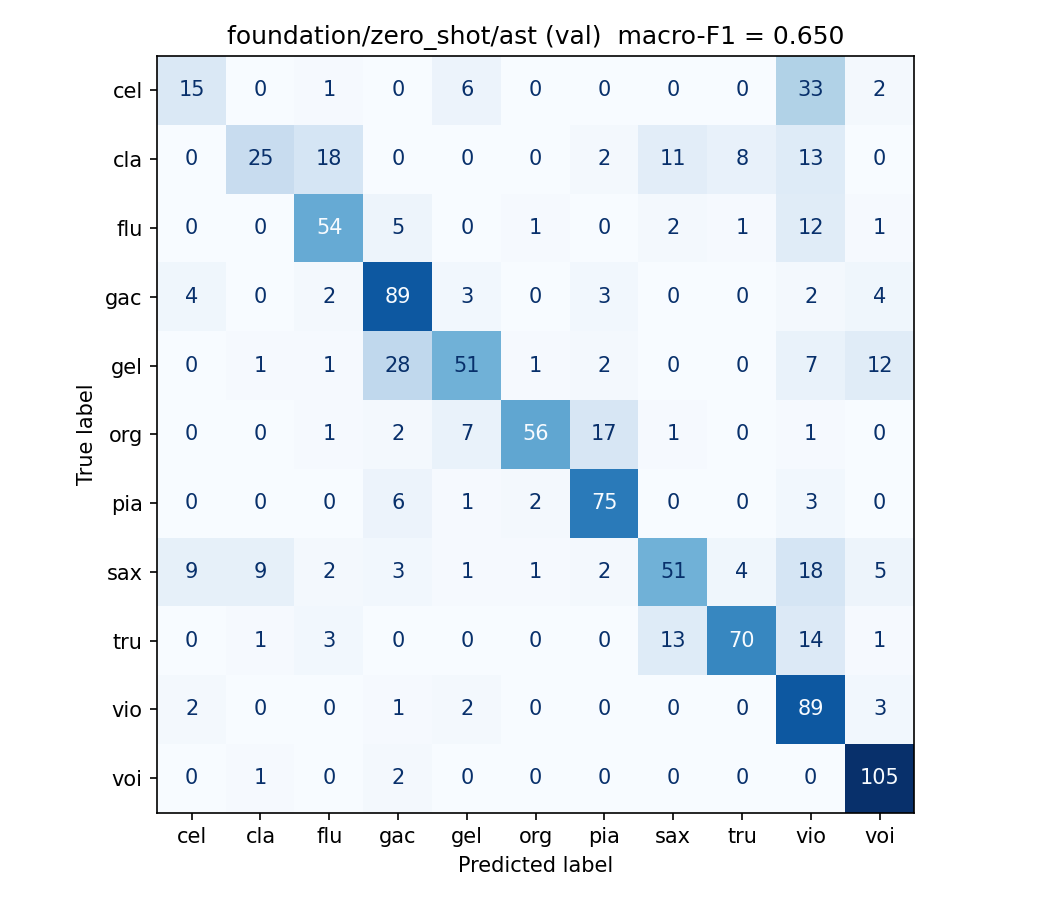

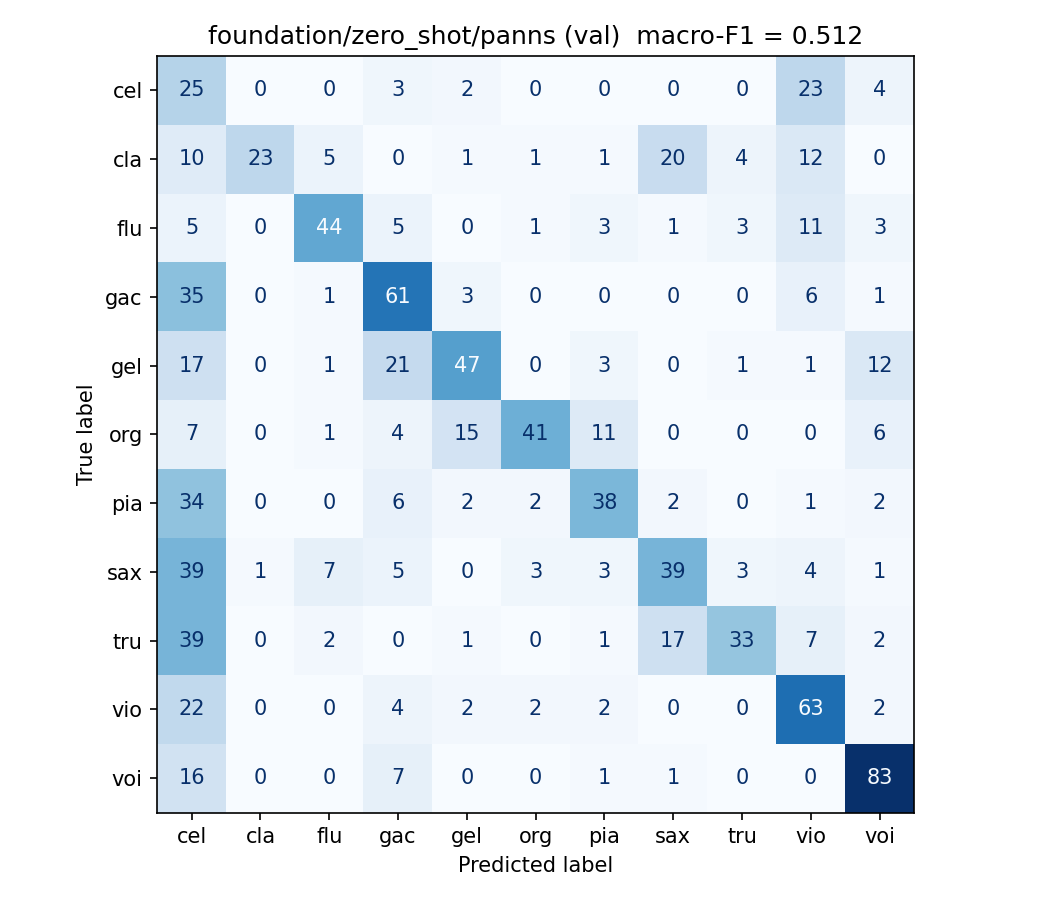

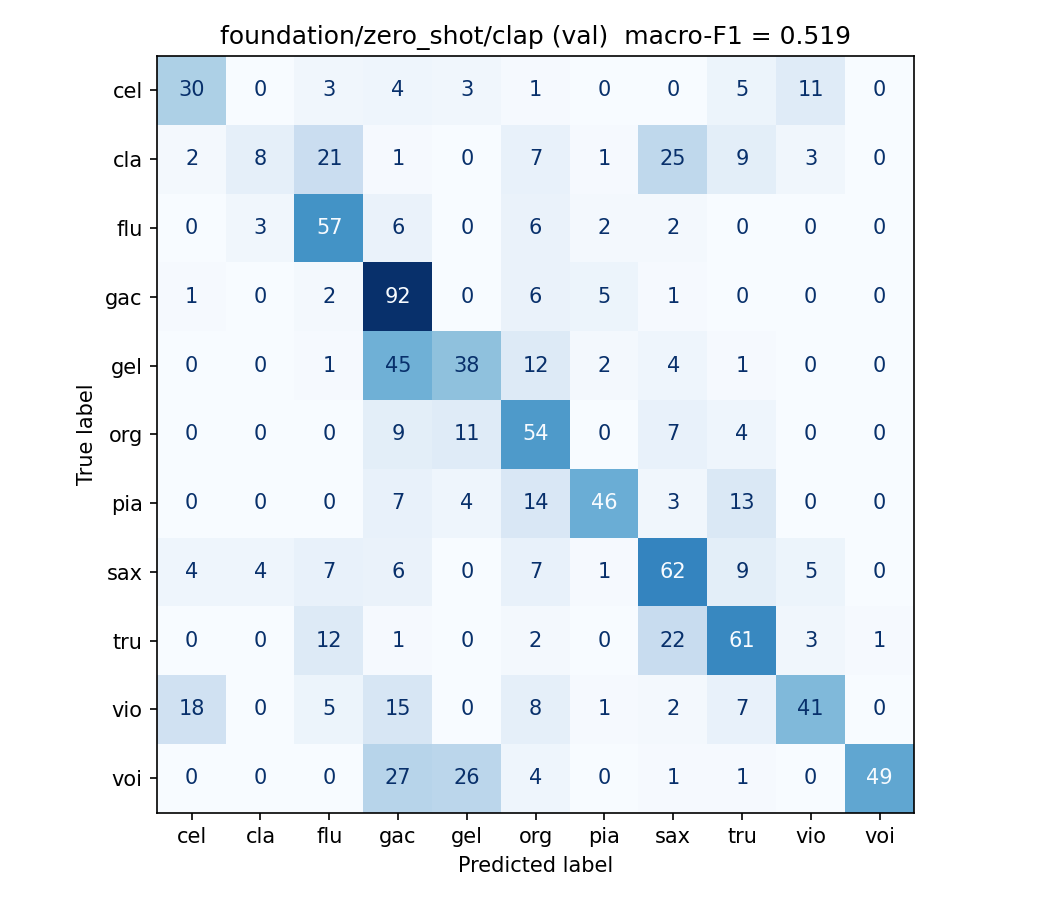

In [ ]:
import pandas as pd
from IPython.display import Image, display
display(pd.read_csv('results/foundation/zero_shot/results.csv'))
print('CLAP prompt templates (val):')
display(pd.read_csv('results/foundation/zero_shot/clap_prompts.csv'))
for m in ['ast', 'panns', 'clap']:
    display(Image(f'results/foundation/zero_shot/{m}/val_confusion.png', width=450))

## 4. Linear probe (frozen backbone)
Logistic regression on the cached embeddings (AST 768-d, PANNs 2048-d, CLAP 512-d) for every training subset, with `C` chosen on val. This is cheap and is the fairest "how good are the features?" comparison with the CNN.

In [ ]:
!python -m src.foundation.finetune.train_finetune --mode probe
save_to_drive()
display(pd.read_csv('results/foundation/finetune/results.csv'))

irmas_prep/manifest.csv not found; rebuilding the same manifest from /content/repo/results/splits
device=cuda  clips=6705  mode=probe  run=probe
[ast probe] subset   5%  n_train=236  seed=0
    val macro-F1 0.676  acc 0.696
[ast probe] subset  10%  n_train=474  seed=0
    val macro-F1 0.721  acc 0.733
[ast probe] subset  25%  n_train=1174  seed=0
    val macro-F1 0.767  acc 0.776
[ast probe] subset  50%  n_train=2358  seed=0
    val macro-F1 0.785  acc 0.795
[ast probe] subset 100%  n_train=4702  seed=0
    val macro-F1 0.803  acc 0.809

ast probe: mean over seeds
           val_macro_f1          
                   mean std count
subset_pct                       
5                0.6757 NaN     1
10               0.7208 NaN     1
25               0.7669 NaN     1
50               0.7854 NaN     1
100              0.8034 NaN     1

[panns probe] subset   5%  n_train=236  seed=0
Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen 

,model,run,subset_pct,seed,n_train,best_C,val_macro_f1,val_acc
0,ast,probe,5,0,236,0.10,0.6757,0.6962
1,ast,probe,10,0,474,0.01,0.7208,0.7331
2,ast,probe,25,0,1174,0.01,0.7669,0.7759
3,ast,probe,50,0,2358,0.01,0.7854,0.7948
4,ast,probe,100,0,4702,0.01,0.8034,0.8088


## 5. Fine-tuning
A new 11-way head plus the **top 2 blocks** of each backbone are trained (`--unfreeze 2`; use `0` for head only, `-1` for the whole model). Same recipe as the CNN: class-weighted cross-entropy, AdamW, early stopping on val macro-F1, 3 seeds.

**Start with the quick check below** (one model, 100%, one seed) to see timing on your GPU. Then run the full grids. Results are written after every run, so if Colab disconnects, re-run setup and continue with the subsets/seeds that are missing (`--subsets ... --seeds ...`).

In [ ]:
# Quick check: AST, 100% subset, seed 0
!python -m src.foundation.finetune.train_finetune --mode finetune --models ast --subsets 100 --seeds 0
save_to_drive()

irmas_prep/manifest.csv not found; rebuilding the same manifest from /content/repo/results/splits
device=cuda  clips=6705  mode=finetune  run=ft_top2
[ast ft_top2] subset 100%  n_train=4702  seed=0
Loading weights: 100% 203/203 [00:00<00:00, 768.11it/s]
    epoch   1  loss 0.780  val macro-F1 0.799  *  (178s)
    epoch   2  loss 0.481  val macro-F1 0.769  (356s)
    epoch   3  loss 0.350  val macro-F1 0.779  (533s)
    epoch   4  loss 0.247  val macro-F1 0.775  (711s)
    epoch   5  loss 0.129  val macro-F1 0.797  (887s)
    val macro-F1 0.799  acc 0.805

ast ft_top2: mean over seeds
           val_macro_f1          
                   mean std count
subset_pct                       
100              0.7993 NaN     1

saved to /content/drive/MyDrive/neural_band


In [ ]:
import os


# Full data-scarcity grid: AST (5 subsets x 3 seeds)
!python -m src.foundation.finetune.train_finetune --mode finetune --models ast
save_to_drive()

irmas_prep/manifest.csv not found; rebuilding the same manifest from /content/repo/results/splits
device=cuda  clips=6705  mode=finetune  run=ft_top2
[ast ft_top2] subset   5%  n_train=236  seed=0
preprocessor_config.json: 100% 297/297 [00:00<00:00, 1.18MB/s]
config.json: 100% 26.8k/26.8k [00:00<00:00, 41.2MB/s]

model.safetensors: downloading bytes:  97% 334M/346M [00:01<00:00, 259MB/s, 29.5MB/s  ]
model.safetensors: downloading bytes: 100% 334M/334M [00:08<00:00, 40.9MB/s, 31.1MB/s  ]
model.safetensors: reconstructing file: 100% 346M/346M [00:08<00:00, 42.4MB/s, 29.0MB/s  ]
Loading weights: 100% 203/203 [00:00<00:00, 7612.30it/s]
    epoch   1  loss 1.333  val macro-F1 0.650  *  (35s)
    epoch   2  loss 0.248  val macro-F1 0.673  *  (68s)
    epoch   3  loss 0.078  val macro-F1 0.649  (102s)
    epoch   4  loss 0.018  val macro-F1 0.675  *  (139s)
    epoch   5  loss 0.004  val macro-F1 0.683  *  (178s)
    epoch   6  loss 0.002  val macro-F1 0.691  *  (217s)
    epoch   7  loss 0.0

In [ ]:
# PANNs (CNN14). Its own SpecAugment is active during fine-tuning.
!python -m src.foundation.finetune.train_finetune --mode finetune --models panns
save_to_drive()

irmas_prep/manifest.csv not found; rebuilding the same manifest from /content/repo/results/splits
device=cuda  clips=6705  mode=finetune  run=ft_top2
[panns ft_top2] subset   5%  n_train=236  seed=0
--2026-11-12 15:35:07--  http://storage.googleapis.com/us_audioset/youtube_corpus/v1/csv/class_labels_indices.csv
Resolving storage.googleapis.com (storage.googleapis.com)... 173.194.203.207, 192.178.163.207, 74.125.20.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|173.194.203.207|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14675 (14K) [application/octet-stream]
Saving to: ‘/root/panns_data/class_labels_indices.csv’

/root/panns_data/cl 100%[===================>]  14.33K  --.-KB/s    in 0s      

2026-11-12 15:35:07 (116 MB/s) - ‘/root/panns_data/class_labels_indices.csv’ saved [14675/14675]

Checkpoint path: /root/panns_data/Cnn14_mAP=0.431.pth
--2026-11-12 15:35:07--  https://zenodo.org/record/3987831/files/Cnn14_mAP%3D0.431.pth?downloa

In [ ]:
# ===== RESUME after a Colab reset: run this first, then cells 5, 6, 7 =====
import os
from google.colab import drive
drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/neural_band'
REPO  = '/content/repo'

if not os.path.exists(REPO):
    from getpass import getpass
    token = getpass('GitHub token (just press Enter if the repo is public): ')
    url = f'https://{token}@github.com/Srija-d/Neural-Band-instrument-recognition-.git' if token \
          else 'https://github.com/Srija-d/Neural-Band-instrument-recognition-.git'
    os.system(f'git clone -q {url} {REPO}')
os.chdir(REPO)
!pip install -q -r requirements.txt

os.makedirs('data', exist_ok=True)
if not os.path.exists('data/IRMAS-TrainingData'):
    !cp "{DRIVE}/IRMAS-TrainingData.zip" data/
    !python scripts/download_irmas.py

!mkdir -p cache/foundation results/foundation
!rsync -a "{DRIVE}/cache_foundation/" cache/foundation/
!rsync -a "{DRIVE}/results_foundation/" results/foundation/

def save_to_drive():
    os.system(f'rsync -a results/foundation/ "{DRIVE}/results_foundation/"')
    os.system(f'rsync -a cache/foundation/ "{DRIVE}/cache_foundation/"')
    print('saved to', DRIVE)

print('folder:', os.getcwd())
print('clips:', len([f for _, _, fs in os.walk('data/IRMAS-TrainingData') for f in fs if f.endswith('.wav')]))

Mounted at /content/drive


In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/neural_band'
REPO  = '/content/repo'

if not os.path.exists(REPO):
    from getpass import getpass
    token = getpass('GitHub token (press Enter if the repo is public): ')
    url = (f'https://{token}@' if token else 'https://') + 'github.com/Srija-d/Neural-Band-instrument-recognition-.git'
    os.system(f'git clone -q {url} {REPO}')
os.chdir(REPO)
!pip install -q -r requirements.txt

os.makedirs('data', exist_ok=True)
if not os.path.exists('data/IRMAS-TrainingData'):
    !cp "{DRIVE}/IRMAS-TrainingData.zip" data/
    !python scripts/download_irmas.py

!mkdir -p cache/foundation results/foundation
!rsync -a "{DRIVE}/cache_foundation/" cache/foundation/
!rsync -a "{DRIVE}/results_foundation/" results/foundation/

def save_to_drive():
    os.system(f'rsync -a results/foundation/ "{DRIVE}/results_foundation/"')
    os.system(f'rsync -a cache/foundation/ "{DRIVE}/cache_foundation/"')
    print('saved to', DRIVE)

print('folder:', os.getcwd())
print('clips :', sum(f.endswith('.wav') for _, _, fs in os.walk('data/IRMAS-TrainingData') for f in fs))

Mounted at /content/drive
Extracting...
Done: 6705 wav files in /content/repo/data/IRMAS-TrainingData
folder: /content/repo
clips : 6705


In [ ]:


# CLAP audio encoder (text tower stays frozen)
!python -m src.foundation.finetune.train_finetune --mode finetune --models clap
save_to_drive()

irmas_prep/manifest.csv not found; rebuilding the same manifest from /content/repo/results/splits
device=cuda  clips=6705  mode=finetune  run=ft_top2
[clap ft_top2] subset   5%  n_train=236  seed=0
preprocessor_config.json: 100% 541/541 [00:00<00:00, 2.29MB/s]
config.json: 100% 5.39k/5.39k [00:00<00:00, 16.7MB/s]
tokenizer_config.json: 100% 384/384 [00:00<00:00, 2.37MB/s]
vocab.json: 100% 798k/798k [00:00<00:00, 84.3MB/s]
merges.txt: 100% 456k/456k [00:00<00:00, 105MB/s]
tokenizer.json: 100% 2.11M/2.11M [00:00<00:00, 160MB/s]
special_tokens_map.json: 100% 280/280 [00:00<00:00, 1.60MB/s]

pytorch_model.bin: downloading bytes:   3% 18.0M/615M [00:01<00:41, 14.2MB/s,  361kB/s  ]
pytorch_model.bin: downloading bytes:  16% 96.3M/615M [00:02<00:06, 77.7MB/s, 8.26MB/s  ]
pytorch_model.bin: reconstructing file:   3% 16.7M/615M [00:02<01:23, 7.19MB/s, 1.14MB/s  ]
pytorch_model.bin: downloading bytes:  21% 128M/615M [00:02<00:05, 87.6MB/s, 9.89MB/s  ] 
pytorch_model.bin: reconstructing file:   7

In [18]:
import os
os.chdir('/content/repo')
count = lambda: sum(f.endswith('.wav') for _, _, fs in os.walk('data/IRMAS-TrainingData') for f in fs)
print('wav files found:', count())

if count() != 6705:
    !rm -rf data/IRMAS-TrainingData
    !mkdir -p data
    !cp "/content/drive/MyDrive/neural_band/IRMAS-TrainingData.zip" data/
    !python scripts/download_irmas.py
    print('wav files now:', count())

wav files found: 0
Extracting...
Done: 6705 wav files in /content/repo/data/IRMAS-TrainingData
wav files now: 6705


In [19]:
!python -m src.foundation.finetune.train_finetune --mode finetune --models clap --subsets 25 --seeds 0 --epochs 10 --patience 3
save_to_drive()

irmas_prep/manifest.csv not found; rebuilding the same manifest from /content/repo/results/splits
device=cuda  clips=6705  mode=finetune  run=ft_top2
[clap ft_top2] subset  25%  n_train=1174  seed=0
preprocessor_config.json: 100% 541/541 [00:00<00:00, 2.28MB/s]
config.json: 100% 5.39k/5.39k [00:00<00:00, 13.8MB/s]
tokenizer_config.json: 100% 384/384 [00:00<00:00, 2.37MB/s]
vocab.json: 100% 798k/798k [00:00<00:00, 86.0MB/s]
merges.txt: 100% 456k/456k [00:00<00:00, 109MB/s]
tokenizer.json: 100% 2.11M/2.11M [00:00<00:00, 133MB/s]
special_tokens_map.json: 100% 280/280 [00:00<00:00, 1.62MB/s]

pytorch_model.bin: downloading bytes:   4% 25.0M/615M [00:01<00:28, 20.7MB/s,  404kB/s  ]
pytorch_model.bin: downloading bytes:   7% 40.5M/615M [00:01<00:16, 35.7MB/s, 2.40MB/s  ]
pytorch_model.bin: downloading bytes:  28% 172M/615M [00:02<00:03, 125MB/s, 14.1MB/s  ]
pytorch_model.bin: downloading bytes:  33% 200M/615M [00:02<00:02, 165MB/s, 15.4MB/s  ]
pytorch_model.bin: downloading bytes:  37% 227M/

In [20]:
!python -m src.foundation.finetune.train_finetune --mode finetune --models clap --subsets 50 --seeds 0 --epochs 10 --patience 3
save_to_drive()

irmas_prep/manifest.csv not found; rebuilding the same manifest from /content/repo/results/splits
device=cuda  clips=6705  mode=finetune  run=ft_top2
[clap ft_top2] subset  50%  n_train=2358  seed=0
Loading weights: 100% 447/447 [00:00<00:00, 26607.64it/s]
    epoch   1  loss 1.848  val macro-F1 0.727  *  (208s)
    epoch   2  loss 1.068  val macro-F1 0.762  *  (381s)
    epoch   3  loss 0.672  val macro-F1 0.763  *  (560s)
    epoch   4  loss 0.418  val macro-F1 0.795  *  (740s)
    epoch   5  loss 0.244  val macro-F1 0.792  (920s)
    epoch   6  loss 0.127  val macro-F1 0.768  (1099s)
    epoch   7  loss 0.075  val macro-F1 0.782  (1273s)
    val macro-F1 0.795  acc 0.800

clap ft_top2: mean over seeds
           val_macro_f1              
                   mean     std count
subset_pct                           
5                0.6803  0.0257     3
10               0.7265  0.0035     2
25               0.7513     NaN     1
50               0.7949     NaN     1

saved to /content/d

In [22]:
!python -m src.foundation.finetune.train_finetune --mode finetune --models clap --subsets 100 --seeds 0 --epochs 10 --patience 3
save_to_drive()

irmas_prep/manifest.csv not found; rebuilding the same manifest from /content/repo/results/splits
device=cuda  clips=6705  mode=finetune  run=ft_top2
[clap ft_top2] subset 100%  n_train=4702  seed=0
Loading weights: 100% 447/447 [00:00<00:00, 13570.75it/s]
    epoch   1  loss 1.537  val macro-F1 0.752  *  (390s)
    epoch   2  loss 0.747  val macro-F1 0.791  *  (701s)
    epoch   3  loss 0.428  val macro-F1 0.799  *  (996s)
    epoch   4  loss 0.255  val macro-F1 0.809  *  (1291s)
    epoch   5  loss 0.146  val macro-F1 0.806  (1583s)
    epoch   6  loss 0.098  val macro-F1 0.811  *  (1880s)
    epoch   7  loss 0.050  val macro-F1 0.799  (2182s)
    epoch   8  loss 0.037  val macro-F1 0.802  (2481s)
    epoch   9  loss 0.025  val macro-F1 0.805  (2782s)
    val macro-F1 0.811  acc 0.813

clap ft_top2: mean over seeds
           val_macro_f1              
                   mean     std count
subset_pct                           
5                0.6803  0.0257     3
10               0.

In [9]:
# If a run is too slow or runs out of memory, for example:
# !python -m src.foundation.finetune.train_finetune --mode finetune --models ast --batch_size 8 --subsets 5 10 25
# !python -m src.foundation.finetune.train_finetune --mode finetune --models ast --unfreeze 0      # head only (fastest)
# !python -m src.foundation.finetune.train_finetune --mode finetune --models panns --unfreeze -1   # whole model

In [23]:
# Restore AST (5-50%) and CLAP (5-10%) fine-tuning scores that were lost when Colab
# disconnected before save_to_drive(). Values copied from the training logs.
import pandas as pd
cols = ['model', 'run', 'subset_pct', 'seed', 'n_train', 'best_epoch', 'epochs_run', 'val_macro_f1', 'val_acc']
logged = [
    ('ast', 'ft_top2',  5, 0,  236,  6, 10, 0.691, 0.709), ('ast', 'ft_top2',  5, 1,  236,  4,  8, 0.696, 0.714),
    ('ast', 'ft_top2',  5, 2,  236, 17, 20, 0.694, 0.718), ('ast', 'ft_top2', 10, 0,  474,  6, 10, 0.730, 0.743),
    ('ast', 'ft_top2', 10, 1,  474,  4,  8, 0.727, 0.739), ('ast', 'ft_top2', 10, 2,  474, 10, 14, 0.732, 0.745),
    ('ast', 'ft_top2', 25, 0, 1174,  4,  8, 0.767, 0.775), ('ast', 'ft_top2', 25, 1, 1174,  3,  7, 0.760, 0.769),
    ('ast', 'ft_top2', 25, 2, 1174,  3,  7, 0.765, 0.772), ('ast', 'ft_top2', 50, 0, 2358,  5,  9, 0.792, 0.800),
    ('ast', 'ft_top2', 50, 1, 2358,  1,  5, 0.781, 0.787), ('ast', 'ft_top2', 50, 2, 2358, 10, 14, 0.793, 0.801),
    ('clap', 'ft_top2', 5, 0,  236, 10, 14, 0.651, 0.684), ('clap', 'ft_top2', 5, 1,  236, 15, 19, 0.699, 0.722),
    ('clap', 'ft_top2', 5, 2,  236, 10, 14, 0.691, 0.710), ('clap', 'ft_top2', 10, 0, 474,  8, 12, 0.724, 0.737),
    ('clap', 'ft_top2', 10, 1, 474, 13, 17, 0.729, 0.741),
]
new = pd.DataFrame(logged, columns=cols).assign(source='training log')
path = 'results/foundation/finetune/results.csv'
old = pd.read_csv(path)
key = ['model', 'run', 'subset_pct', 'seed']
new = new[~new.set_index(key).index.isin(old.set_index(key).index)]   # never duplicate a row
pd.concat([old, new], ignore_index=True).to_csv(path, index=False)
print(f'added {len(new)} rows')
save_to_drive()

added 0 rows
saved to /content/drive/MyDrive/neural_band


## 6. Compare with the classical baseline and the CNN
Val macro-F1 against training-set size for every model: the data-scarcity curves for RQ2. Zero-shot uses no training data, so it is a horizontal line.

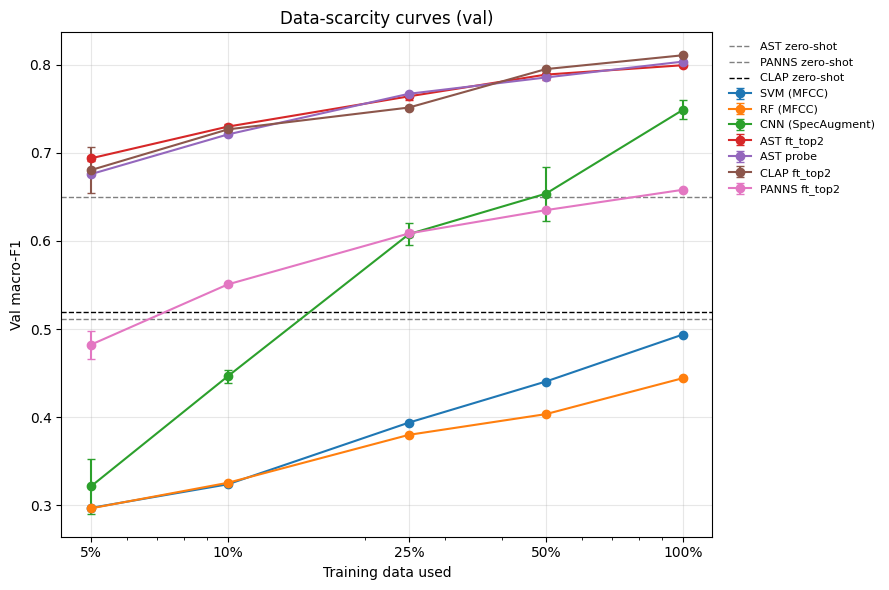

,5%,10%,25%,50%,100%
CLAP ft_top2,0.680,0.726,0.751,0.795,0.811
AST probe,0.676,0.721,0.767,0.785,0.803
AST ft_top2,0.694,0.730,0.764,0.789,0.799
CNN (SpecAugment),0.322,0.447,0.608,0.654,0.749
PANNS ft_top2,0.482,0.551,0.608,0.635,0.658
SVM (MFCC),0.297,0.324,0.394,0.440,0.494
RF (MFCC),0.297,0.326,0.380,0.404,0.444


saved to /content/drive/MyDrive/neural_band


In [24]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

curves = {}
b = pd.read_csv('baseline_results/results.csv')
for m in ['svm', 'rf']:
    curves[f'{m.upper()} (MFCC)'] = b[b.model == m].groupby('subset_pct').val_macro_f1.agg(['mean', 'std'])
c = pd.read_csv('results/cnn/results.csv')
curves['CNN (SpecAugment)'] = c[c.run == 'specaug1_clip3s'].groupby('subset_pct').val_macro_f1.agg(['mean', 'std'])
ft_path = 'results/foundation/finetune/results.csv'
if os.path.exists(ft_path):
    f = pd.read_csv(ft_path)
    for (m, run), g in f.groupby(['model', 'run']):
        curves[f'{m.upper()} {run}'] = g.groupby('subset_pct').val_macro_f1.agg(['mean', 'std'])

fig, ax = plt.subplots(figsize=(9, 6))
for name, s in curves.items():
    ax.errorbar(s.index, s['mean'], yerr=s['std'].fillna(0), marker='o', capsize=3, label=name)
zs_path = 'results/foundation/zero_shot/results.csv'
if os.path.exists(zs_path):
    for _, r in pd.read_csv(zs_path).iterrows():
        ax.axhline(r.val_macro_f1, ls='--', lw=1, label=f'{r.model.upper()} zero-shot', color='gray' if r.model != 'clap' else 'black')
ax.set_xscale('log'); ax.set_xticks([5, 10, 25, 50, 100]); ax.set_xticklabels(['5%', '10%', '25%', '50%', '100%'])
ax.set_xlabel('Training data used'); ax.set_ylabel('Val macro-F1'); ax.set_title('Data-scarcity curves (val)')
ax.grid(alpha=.3); ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
fig.tight_layout(); fig.savefig('results/foundation/data_scarcity_val.png', dpi=150); plt.show()

table = pd.DataFrame({k: v['mean'] for k, v in curves.items()}).T.round(3)
table.columns = [f'{p}%' for p in table.columns]
display(table.sort_values('100%', ascending=False))
save_to_drive()

## 7. Week 7 only: score the test split
Run this **once**, after every model choice has been made on val. It adds `test_macro_f1` columns to the same results files.

In [25]:
# !python -m src.foundation.zero_shot.run_zero_shot --eval_test
# !python -m src.foundation.finetune.train_finetune --mode probe --eval_test
# !python -m src.foundation.finetune.train_finetune --mode finetune --models ast panns clap --eval_test
# save_to_drive()

## 8. Push to GitHub (on a branch, then open a Pull Request)
Only code and small result files are pushed; `cache/` and `checkpoints/` are already in `.gitignore`. You need a GitHub personal access token (Settings → Developer settings → Tokens) with repo access.

In [26]:
# from getpass import getpass
# token = getpass('GitHub token: ')
# !git config user.name "Srija Dwarakacherla" && git config user.email "you@example.com"
# !git checkout -b foundation-models
# !git add src/foundation/common.py src/foundation/zero_shot/run_zero_shot.py src/foundation/finetune/train_finetune.py results/foundation
# !git commit -m "Add foundation models: zero-shot, linear probe and fine-tuning (AST, PANNs, CLAP)"
# !git push https://{token}@github.com/Srija-d/Neural-Band-instrument-recognition-.git foundation-models


import os
from getpass import getpass
os.chdir('/content/repo')

# make sure the results are the full set saved on Drive
!rsync -a "/content/drive/MyDrive/neural_band/results_foundation/" results/foundation/

token = getpass('GitHub token: ')
!git config user.name "Srija-d"
!git config user.email "srija.dwarakacherla@gmail.com"

!git checkout -B foundation-models
!git add src/foundation/common.py src/foundation/zero_shot/run_zero_shot.py src/foundation/finetune/train_finetune.py results/foundation
!git status --short
!git commit -m "Add foundation models: zero-shot, linear probe and fine-tuning (AST, PANNs, CLAP)"
!git push https://{token}@github.com/Srija-d/Neural-Band-instrument-recognition-.git foundation-models

GitHub token: ··········
Switched to a new branch 'foundation-models'
A  results/foundation/data_scarcity_val.png
A  results/foundation/finetune/preds/ast_ft_top2_p100_s0_val.csv
A  results/foundation/finetune/preds/ast_probe_p005_s0_val.csv
A  results/foundation/finetune/preds/ast_probe_p010_s0_val.csv
A  results/foundation/finetune/preds/ast_probe_p025_s0_val.csv
A  results/foundation/finetune/preds/ast_probe_p050_s0_val.csv
A  results/foundation/finetune/preds/ast_probe_p100_s0_val.csv
A  results/foundation/finetune/preds/clap_ft_top2_p025_s0_val.csv
A  results/foundation/finetune/preds/clap_ft_top2_p050_s0_val.csv
A  results/foundation/finetune/preds/clap_ft_top2_p100_s0_val.csv
A  results/foundation/finetune/preds/panns_ft_top2_p005_s0_val.csv
A  results/foundation/finetune/preds/panns_ft_top2_p005_s1_val.csv
A  results/foundation/finetune/preds/panns_ft_top2_p005_s2_val.csv
A  results/foundation/finetune/preds/panns_ft_top2_p010_s0_val.csv
A  results/foundation/finetune/preds/pan

In [28]:
from getpass import getpass
token = getpass('GitHub token: ').strip()
print('token length:', len(token), '| starts with:', token[:4])   # should be ~40 chars, ghp_ or github_pat_
!git push https://{token}@github.com/Srija-d/Neural-Band-instrument-recognition-.git foundation-models

GitHub token: ··········
token length: 40 | starts with: ghp_
Enumerating objects: 72, done.
Counting objects: 100% (72/72), done.
Delta compression using up to 2 threads
Compressing objects: 100% (68/68), done.
Writing objects: 100% (68/68), 355.45 KiB | 8.89 MiB/s, done.
Total 68 (delta 31), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (31/31), completed with 3 local objects.
remote: 
remote: Create a pull request for 'foundation-models' on GitHub by visiting:
remote:      https://github.com/Srija-d/Neural-Band-instrument-recognition-/pull/new/foundation-models
remote: 
To https://github.com/Srija-d/Neural-Band-instrument-recognition-.git
 * [new branch]      foundation-models -> foundation-models
